# 04 – Evaluation
This notebook covers the Evaluation phase (CRISP-DM):
1. Evaluation of the model results
2. Detailed error analysis of the best model
3. Review of the process
4. Model saving and reload check
5. Next phase for the chosen model

Run notebook **03_modelling** first, because this notebook uses its saved results.

In [1]:
# COLAB ONLY (skip on laptop)
# %cd /content/tetouan-power-consumption-dl/notebooks

In [2]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from tensorflow import keras

sns.set_theme(style="whitegrid")
DATA_DIR, MODEL_DIR, RESULTS_DIR, FIG_DIR = "../data/processed", "../models", "../results", "../figures"

results_df = pd.read_csv(f"{RESULTS_DIR}/model_results.csv")
summary    = pd.read_csv(f"{RESULTS_DIR}/model_summary.csv", index_col=0)
pred_file  = np.load(f"{RESULTS_DIR}/predictions.npz")

eval_index = pd.to_datetime(pred_file["index"])
y_true     = pred_file["y_true"]
MODELS     = [m for m in pred_file.files if m not in ("index", "y_true")]
preds      = {m: pred_file[m] for m in MODELS}
TARGETS    = ["Zone1", "Zone2", "Zone3"]
print("Models:", MODELS)

Models: ['Naive', 'LinearRegression', 'RandomForest', 'MLP', 'LSTM', 'GRU']


## 1. Model evaluation results

In [3]:
print("Average over the 3 zones, sorted by RMSE:")
summary

Average over the 3 zones, sorted by RMSE:


,MAE,RMSE,R2,MAPE (%),Train time (s)
Model,,,,,
LinearRegression,1104.850,1621.932,0.932,4.971,0.035
LSTM,1133.380,1628.971,0.932,5.169,274.017
MLP,1206.029,1680.891,0.929,5.757,19.293
RandomForest,1192.395,1740.953,0.919,5.326,4.252
GRU,1309.629,1751.909,0.920,5.693,152.850
Naive,1173.923,1756.398,0.916,5.327,0.000


### 1.1 Improvement over the naive baseline
A model is only useful if it clearly beats the simple rule "tomorrow will be like today".

In [4]:
rmse = results_df.pivot(index="Model", columns="Zone", values="RMSE")
improvement = ((1 - rmse.div(rmse.loc["Naive"], axis=1)) * 100).drop("Naive")
improvement["Average"] = improvement.mean(axis=1)
improvement = improvement.sort_values("Average", ascending=False).round(1)
print("RMSE reduction compared with the naive baseline (%):")
improvement

RMSE reduction compared with the naive baseline (%):


Zone,Zone1,Zone2,Zone3,Average
Model,,,,
LinearRegression,3.6,16.6,1.2,7.1
LSTM,6.3,16.5,-4.7,6.0
MLP,7.7,18.7,-22.4,1.3
RandomForest,7.3,1.6,-10.9,-0.7
GRU,0.1,8.3,-11.3,-1.0


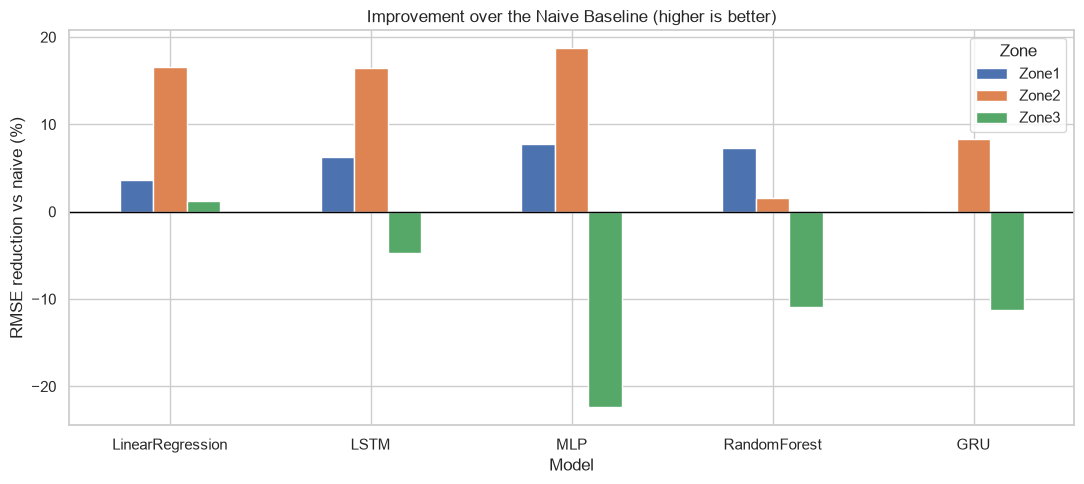

In [5]:
improvement.drop(columns="Average").plot(kind="bar", figsize=(11, 5), rot=0)
plt.axhline(0, color="black", lw=1)
plt.ylabel("RMSE reduction vs naive (%)")
plt.title("Improvement over the Naive Baseline (higher is better)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/16_improvement_vs_naive.png", dpi=150); plt.show()

### 1.2 Choose the best model
The best model is the one with the lowest average RMSE (excluding the naive baseline).

In [6]:
BEST = summary.drop("Naive").index[0]
print("Best model:", BEST)
summary.loc[[BEST, "Naive"]]

Best model: LinearRegression


,MAE,RMSE,R2,MAPE (%),Train time (s)
Model,,,,,
LinearRegression,1104.850,1621.932,0.932,4.971,0.035
Naive,1173.923,1756.398,0.916,5.327,0.000


## 2. Error analysis of the best model

### 2.1 Actual vs predicted – one summer week and one winter week

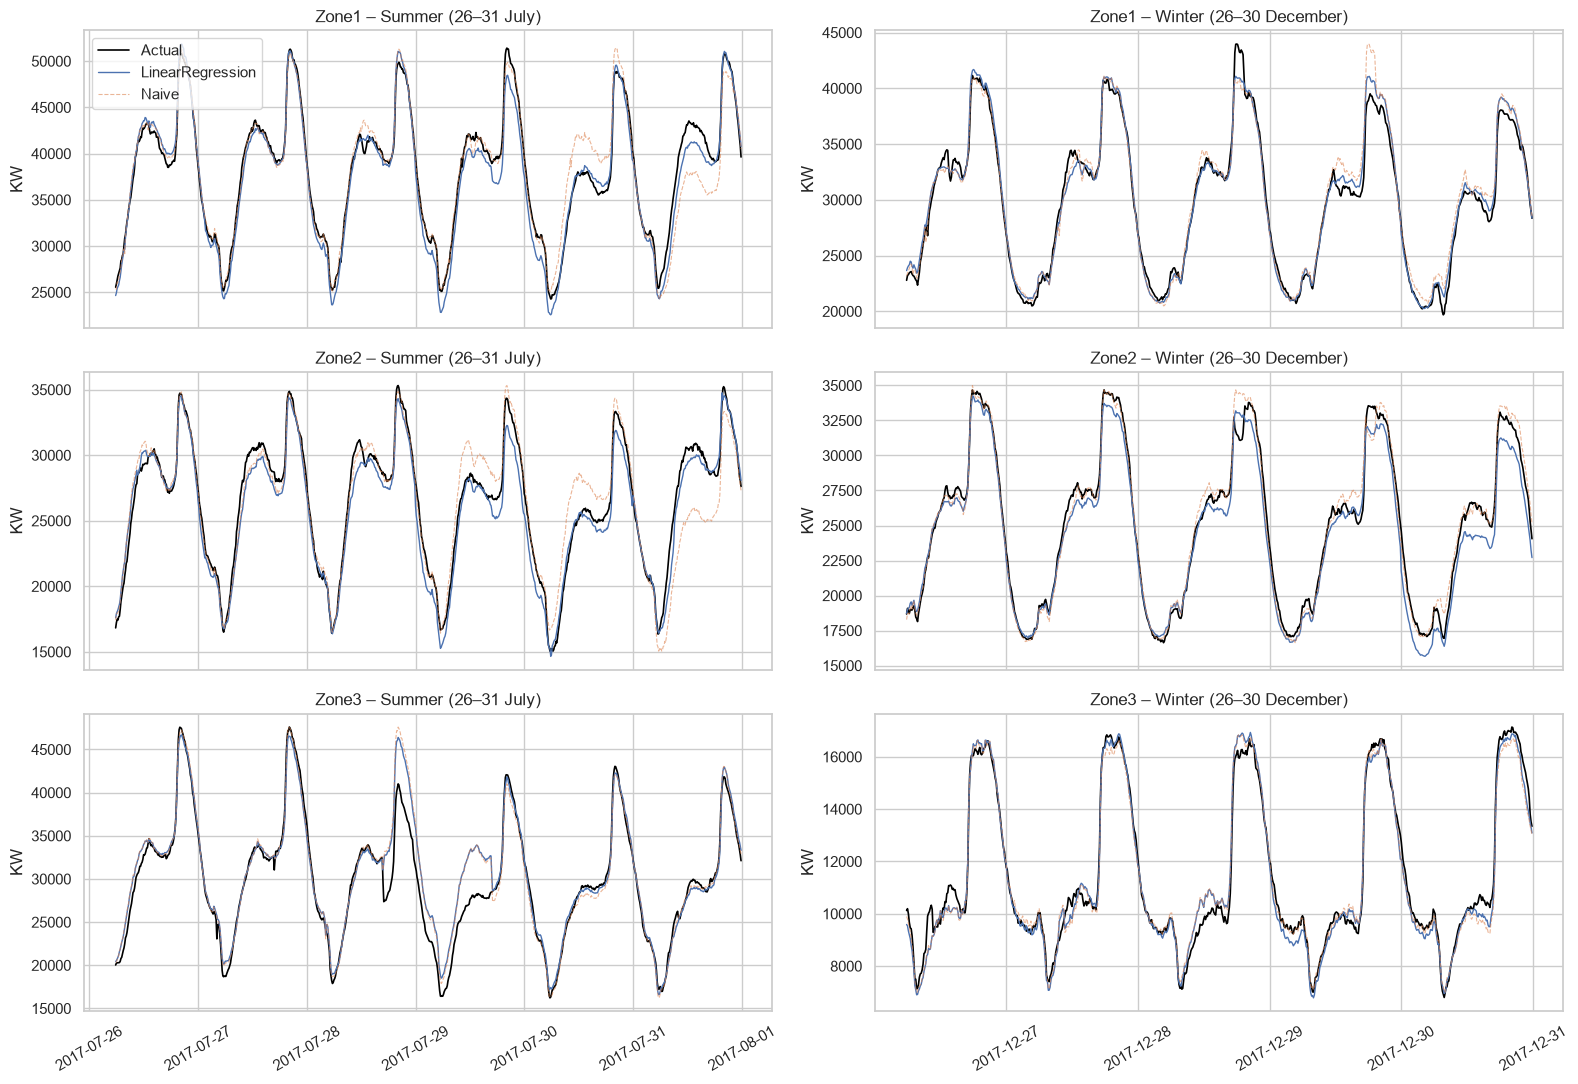

In [7]:
best_df = pd.DataFrame(preds[BEST], index=eval_index, columns=TARGETS)
true_df = pd.DataFrame(y_true,      index=eval_index, columns=TARGETS)
naive_df = pd.DataFrame(preds["Naive"], index=eval_index, columns=TARGETS)

periods = {"Summer (26–31 July)": ("2017-07-26", "2017-07-31 23:50"),
           "Winter (26–30 December)": ("2017-12-26", "2017-12-30 23:50")}

fig, axes = plt.subplots(3, 2, figsize=(16, 11), sharex="col")
for col, (title, (start, end)) in enumerate(periods.items()):
    for row, z in enumerate(TARGETS):
        ax = axes[row, col]
        ax.plot(true_df.loc[start:end, z],  label="Actual", color="black", lw=1.2)
        ax.plot(best_df.loc[start:end, z],  label=BEST, lw=1)
        ax.plot(naive_df.loc[start:end, z], label="Naive", lw=0.8, alpha=0.6, ls="--")
        ax.set_title(f"{z} – {title}")
        ax.set_ylabel("KW")
axes[0, 0].legend()
for ax in axes[-1]: ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/17_actual_vs_predicted.png", dpi=150); plt.show()

### 2.2 Predicted vs actual scatter (perfect model = diagonal line)

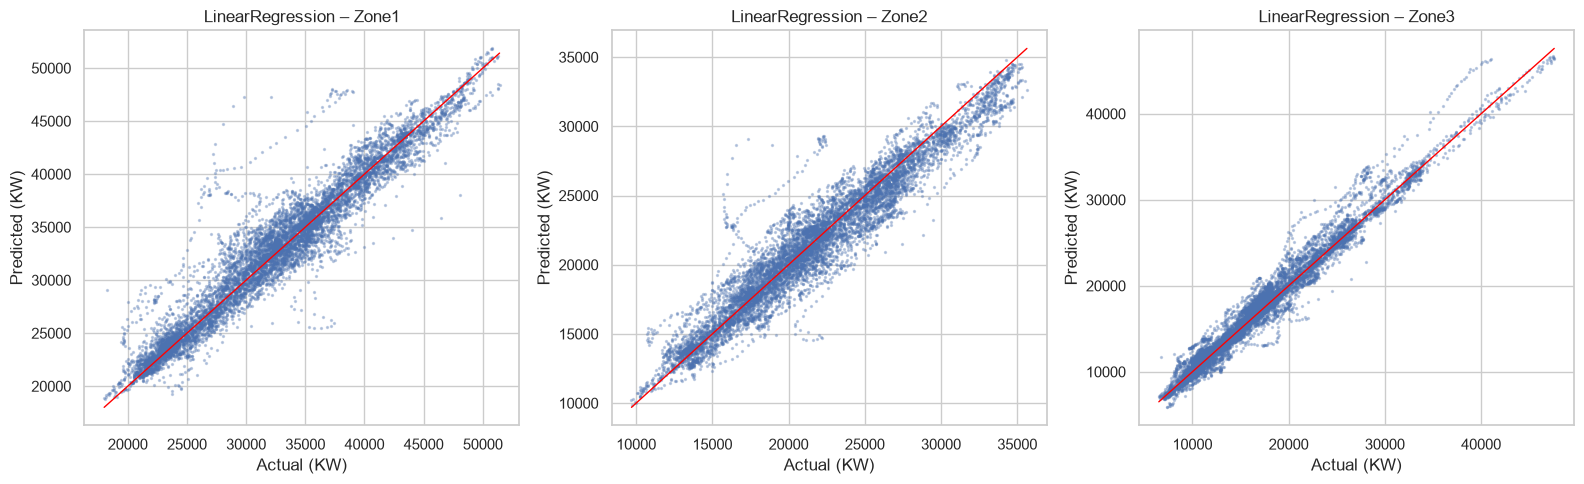

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, z in zip(axes, TARGETS):
    ax.scatter(true_df[z], best_df[z], s=2, alpha=0.3)
    lims = [true_df[z].min(), true_df[z].max()]
    ax.plot(lims, lims, color="red", lw=1)
    ax.set_xlabel("Actual (KW)"); ax.set_ylabel("Predicted (KW)")
    ax.set_title(f"{BEST} – {z}")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/18_scatter_pred_vs_actual.png", dpi=150); plt.show()

### 2.3 Residuals (errors)

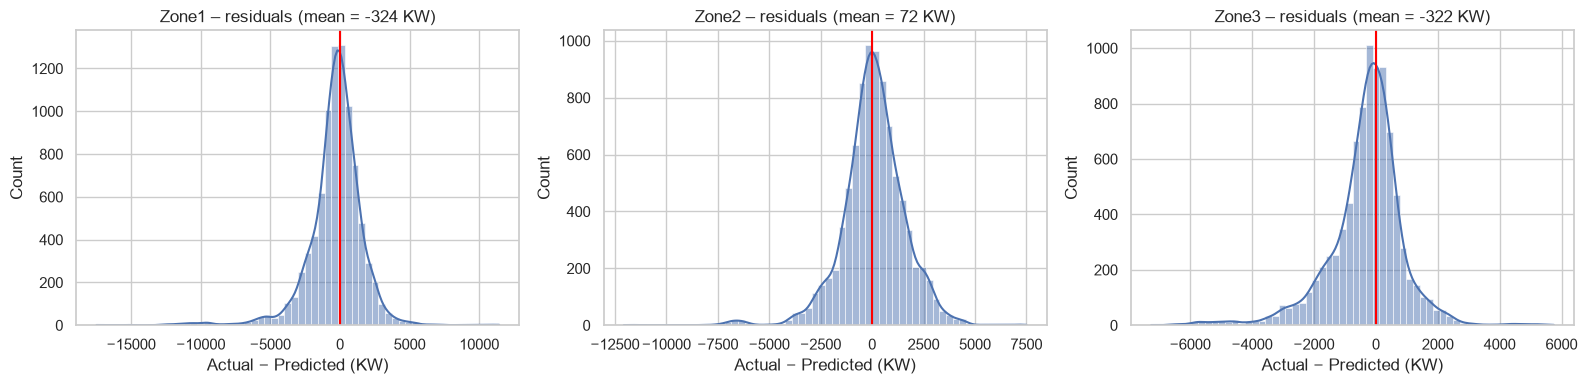

In [9]:
residuals = true_df - best_df

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, z in zip(axes, TARGETS):
    sns.histplot(residuals[z], bins=60, kde=True, ax=ax)
    ax.axvline(0, color="red")
    ax.set_title(f"{z} – residuals (mean = {residuals[z].mean():.0f} KW)")
    ax.set_xlabel("Actual − Predicted (KW)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/19_residuals.png", dpi=150); plt.show()

### 2.4 When does the model make the biggest errors?

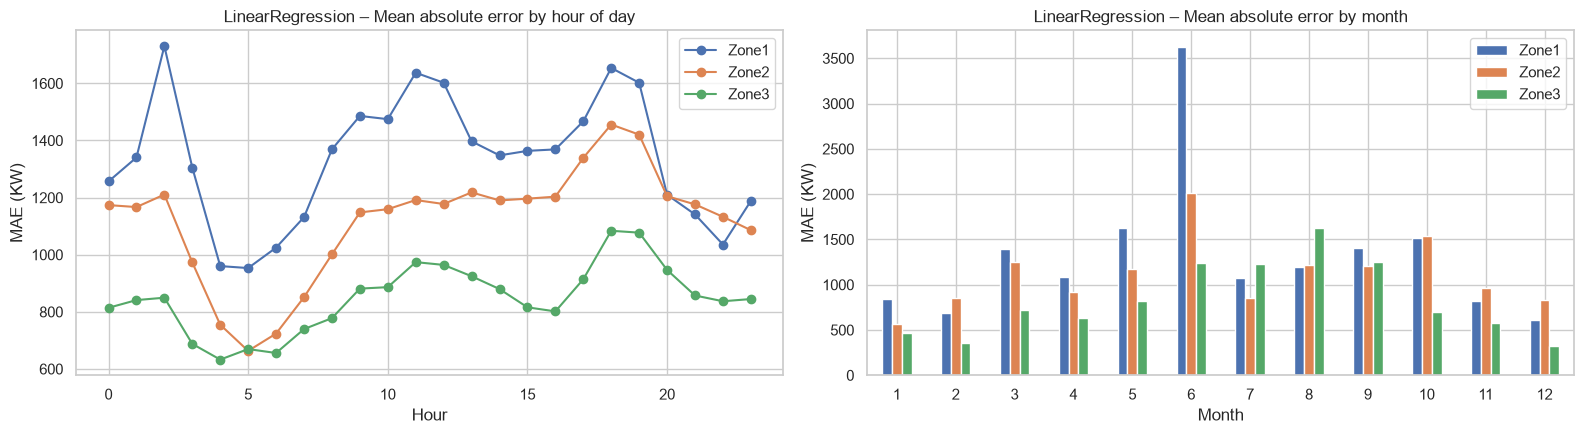

In [10]:
abs_err = residuals.abs()
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))

abs_err.groupby(abs_err.index.hour).mean().plot(marker="o", ax=axes[0])
axes[0].set_title(f"{BEST} – Mean absolute error by hour of day")
axes[0].set_xlabel("Hour"); axes[0].set_ylabel("MAE (KW)")

abs_err.groupby(abs_err.index.month).mean().plot(kind="bar", ax=axes[1], rot=0)
axes[1].set_title(f"{BEST} – Mean absolute error by month")
axes[1].set_xlabel("Month"); axes[1].set_ylabel("MAE (KW)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/20_error_by_hour_month.png", dpi=150); plt.show()

### 2.5 Business view – error at the evening peak (18:00–22:00)

In [11]:
peak = (eval_index.hour >= 18) & (eval_index.hour < 22)
business = pd.DataFrame({
    "Mean consumption (KW)": true_df.mean(),
    "MAE all hours (KW)":    abs_err.mean(),
    "MAE peak hours (KW)":   abs_err[peak].mean(),
    "Error as % of mean":    abs_err.mean() / true_df.mean() * 100,
}).round(1)
business

,Mean consumption (KW),MAE all hours (KW),MAE peak hours (KW),Error as % of mean
Zone1,32512.2,1338.6,1401.8,4.1
Zone2,21617.9,1123.1,1314.4,5.2
Zone3,17548.0,852.9,991.3,4.9


## 3. Review of the process
Use these questions to write the *review process* part of your report (in your own words):
- **Data leakage:** lag features only use data ≥ 24 h old; scalers were fitted on train only;
  the test set was used only once at the end.
- **Split:** the monthly block split puts every season in train, validation and test.
- **Overfitting:** look at the learning curves (figure 14). Are training and validation loss close?
- **Baseline:** did every model beat the naive baseline (section 1.1)? Which one did not, and why?
- **Zones:** which zone is hardest to predict, and does the EDA explain why?
- **Cost vs benefit:** compare training time with the accuracy gain (summary table).

## 4. Model saving and reload check

Models were saved in notebook 03: neural networks in the native Keras format (`.keras`, HDF5-based)
and classical models with `joblib` (pickle). Here we reload the best model from disk and check that
it gives exactly the same predictions, which shows it is ready for deployment.

In [12]:
cfg = joblib.load(f"{MODEL_DIR}/feature_config.pkl")
target_scaler = joblib.load(f"{MODEL_DIR}/target_scaler.pkl")
FEATURES = cfg["FEATURES"]
WINDOW = 36

MODEL_FILES = {"LinearRegression": "linear_regression.pkl", "RandomForest": "random_forest.pkl",
               "MLP": "mlp.keras", "LSTM": "lstm.keras", "GRU": "gru.keras"}
SEQUENCE_MODELS = {"LSTM", "GRU"}

path = f"{MODEL_DIR}/{MODEL_FILES[BEST]}"
model = keras.models.load_model(path) if path.endswith(".keras") else joblib.load(path)

test = pd.read_csv(f"{DATA_DIR}/test.csv", index_col="DateTime", parse_dates=True)
if BEST in SEQUENCE_MODELS:
    X_list = []
    for _, block in test.groupby(test.index.month):
        X = block[FEATURES].values.astype("float32")
        X_list.append(np.lib.stride_tricks.sliding_window_view(X, WINDOW, axis=0).transpose(0, 2, 1))
    X_check = np.concatenate(X_list)
    reloaded = model.predict(X_check, verbose=0)
else:
    X_check = test.loc[eval_index, FEATURES].values
    reloaded = model.predict(X_check)

reloaded_kw = target_scaler.inverse_transform(reloaded)
print("Reloaded model:", path)
print("Same predictions as in notebook 03:", np.allclose(reloaded_kw, preds[BEST], rtol=1e-3, atol=1.0))

Reloaded model: ../models/linear_regression.pkl
Same predictions as in notebook 03: True


In [13]:
deploy_info = {
    "best_model": BEST,
    "model_file": MODEL_FILES[BEST],
    "is_sequence_model": BEST in SEQUENCE_MODELS,
    "window": WINDOW,
    "features": FEATURES,
    "targets": TARGETS,
    "test_metrics": summary.loc[BEST].round(3).to_dict(),
}
with open(f"{MODEL_DIR}/best_model.json", "w") as f:
    json.dump(deploy_info, f, indent=2)
print(json.dumps(deploy_info, indent=2))

{
  "best_model": "LinearRegression",
  "model_file": "linear_regression.pkl",
  "is_sequence_model": false,
  "window": 36,
  "features": [
    "Temperature",
    "Humidity",
    "WindSpeed",
    "GeneralDiffuseFlows",
    "DiffuseFlows",
    "time_sin",
    "time_cos",
    "dow_sin",
    "dow_cos",
    "month_sin",
    "month_cos",
    "is_weekend",
    "Zone1_lag1d",
    "Zone2_lag1d",
    "Zone3_lag1d",
    "Zone1_lag7d",
    "Zone2_lag7d",
    "Zone3_lag7d",
    "Zone1_mean1d",
    "Zone2_mean1d",
    "Zone3_mean1d"
  ],
  "targets": [
    "Zone1",
    "Zone2",
    "Zone3"
  ],
  "test_metrics": {
    "MAE": 1104.85,
    "RMSE": 1621.932,
    "R2": 0.932,
    "MAPE (%)": 4.971,
    "Train time (s)": 0.035
  }
}


## 5. Next phase
The chosen model moves to **deployment** (notebook/app in the `app/` folder): a Flask web app that
loads the saved model and scalers and returns forecasts for the 3 zones.

Ideas for future improvement (for the report):
- Use real weather **forecasts** as inputs (in production, tomorrow's weather is a forecast, not a measurement).
- Add holiday / Ramadan calendar features (Morocco), which affect consumption patterns.
- Hyperparameter tuning (e.g. KerasTuner) and longer training windows.
- More years of data to learn seasonal patterns better.
- Retrain the model regularly (monthly) and monitor its error over time.